# Vox Deorum Analysis: Strategist Comparison

This notebook analyzes game results comparing different strategist conditions (excluding none-strategist).

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Import utility functions and CONDITION_MAPPING from the plot-utilities module
from shared.plot_utilities import (
    load_panel_data,
    setup_notebook_display,
    plot_bar_chart,
    plot_grouped_bar_chart,
    plot_distribution_histograms,
    plot_strategy_radar_charts
)

# Set up notebook display and plotting style
setup_notebook_display(figsize=(10, 6))

# Load panel data using the unified function
panel_df = load_panel_data('../panel_data.csv', condition_include=["observe-vanilla-standard"], skip_mapping=True)
panel_df.head()

✓ Loaded panel data: 1552 rows
✓ Filters applied: condition_include=['observe-vanilla-standard']
✓ Unique conditions: 1
✓ Unique player types: 8

Player Type Distribution:
  Player 0: 194 rows (12.5%)
  Player 1: 194 rows (12.5%)
  Player 2: 194 rows (12.5%)
  Player 3: 194 rows (12.5%)
  Player 4: 194 rows (12.5%)
  Player 5: 194 rows (12.5%)
  Player 6: 194 rows (12.5%)
  Player 7: 194 rows (12.5%)


,experiment,game_id,turn,map_type,map_size,difficulty,game_speed,victory_type,victory_player_id,player_id,civilization,score,score_rank,score_ratio,survival_turn,is_winner,input_tokens,reasoning_tokens,output_tokens,strategy_changes,persona_changes,research_changes,policy_changes,nuke,use_nuke,domination_ratio,culture_ratio,diplomatic_ratio,science_ratio,tradition,authority,progress,fealty,statecraft,artistry,industry,imperialism,rationalism,freedom,autocracy,order,condition,player_type
1296,observe-vanilla-standard,00f7fd19-838b-41fc-9442-bcee8ebaa07d,349,Vox_Deorum,Standard,Prince,Standard,Cultural,2,0,Mongolia,1674,4,0.4571,348,0,NaN,NaN,NaN,181,1,0,0,NaN,NaN,0.8046,0.0000,0.0000,0.1954,NaN,17.0,NaN,134.0,NaN,NaN,NaN,257.0,NaN,NaN,NaN,349.0,observe-vanilla-standard,Player 0
1297,observe-vanilla-standard,00f7fd19-838b-41fc-9442-bcee8ebaa07d,349,Vox_Deorum,Standard,Prince,Standard,Cultural,2,1,Poland,1169,6,0.3192,348,0,NaN,NaN,NaN,168,1,0,0,NaN,NaN,0.0000,0.0000,0.5444,0.4556,18.0,NaN,NaN,NaN,NaN,113.0,NaN,NaN,205.0,NaN,NaN,305.0,observe-vanilla-standard,Player 1
1298,observe-vanilla-standard,00f7fd19-838b-41fc-9442-bcee8ebaa07d,349,Vox_Deorum,Standard,Prince,Standard,Cultural,2,2,Morocco,3662,1,1.0000,348,1,NaN,NaN,NaN,162,1,0,0,NaN,NaN,0.0000,0.4298,0.2837,0.2865,22.0,NaN,NaN,NaN,NaN,120.0,206.0,NaN,NaN,271.0,NaN,NaN,observe-vanilla-standard,Player 2
1299,observe-vanilla-standard,00f7fd19-838b-41fc-9442-bcee8ebaa07d,349,Vox_Deorum,Standard,Prince,Standard,Cultural,2,3,China,2602,3,0.7105,348,0,NaN,NaN,NaN,172,1,0,0,NaN,NaN,0.0287,0.6275,0.0000,0.3438,21.0,NaN,NaN,NaN,NaN,126.0,NaN,NaN,214.0,274.0,NaN,NaN,observe-vanilla-standard,Player 3
1300,observe-vanilla-standard,00f7fd19-838b-41fc-9442-bcee8ebaa07d,349,Vox_Deorum,Standard,Prince,Standard,Cultural,2,4,The Ottomans,980,7,0.2676,263,0,NaN,NaN,NaN,133,1,0,0,NaN,NaN,0.5682,0.0000,0.0000,0.4318,NaN,NaN,17.0,151.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,observe-vanilla-standard,Player 4


## 1. Win Rate of Each Player by Condition

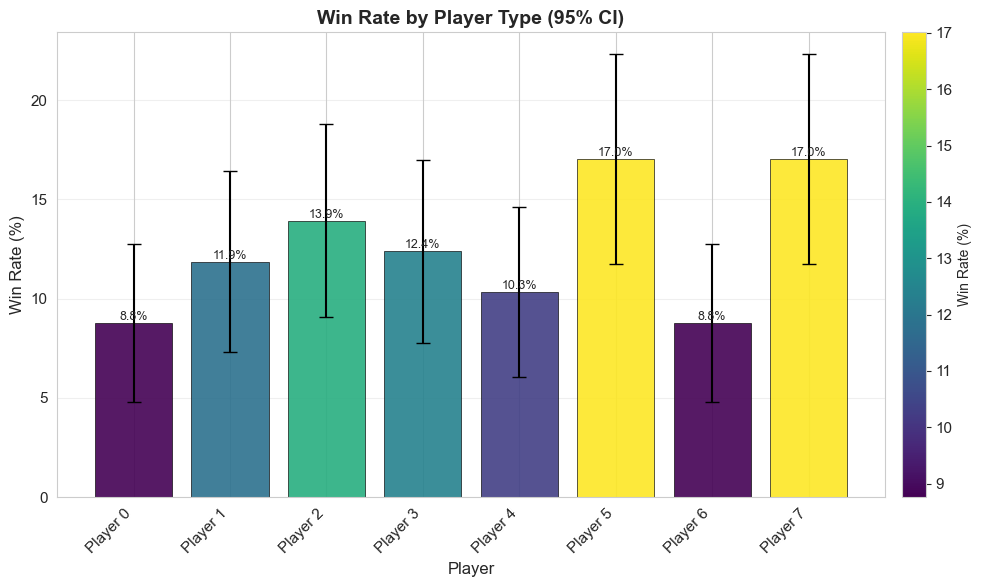

,is_winner=1
Player 0,17/194 (8.8%)
Player 1,23/194 (11.9%)
Player 2,27/194 (13.9%)
Player 3,24/194 (12.4%)
Player 4,20/194 (10.3%)
Player 5,33/194 (17.0%)
Player 6,17/194 (8.8%)
Player 7,33/194 (17.0%)


In [2]:
# Create the chart and print summary  
plot_bar_chart(
    panel_df,
    value_col='is_winner',
    category_col='player_type',
    xlabel='Player',
    ylabel='Win Rate (%)',
    title='Win Rate by Player Type',
    use_percentage=True,
    show_error_bars=True
)

## 2. Victory Type Distribution by Condition

Analyzing the types of victories (Cultural, Diplomatic, Domination, Science, Time) across conditions.

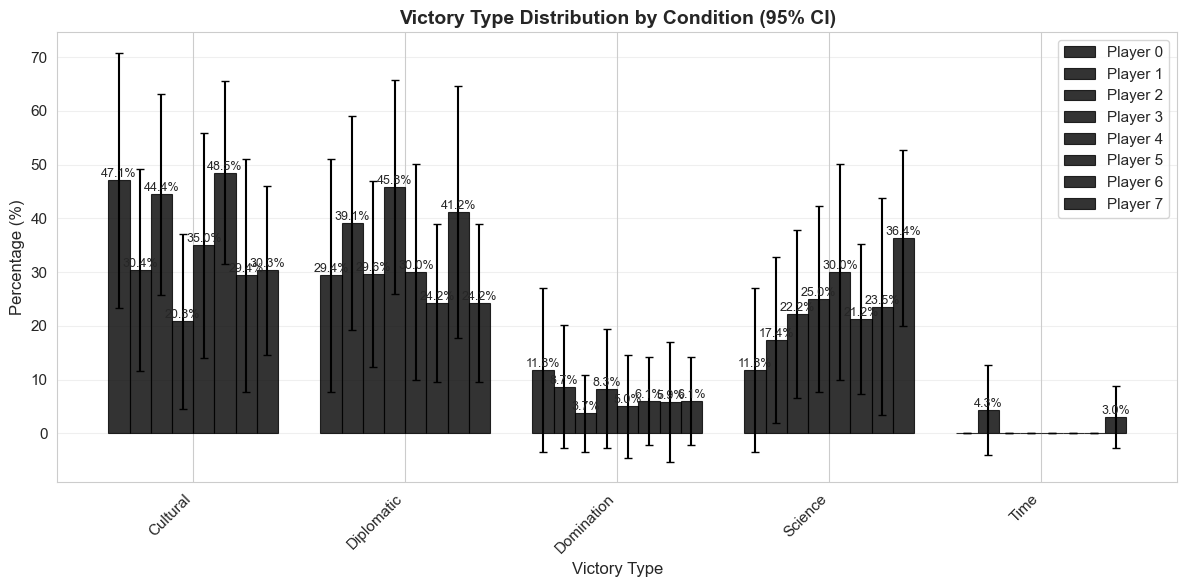

victory_type,Cultural,Diplomatic,Domination,Science,Time
Player 0,8 (47.1%),5 (29.4%),2 (11.8%),2 (11.8%),0 (0.0%)
Player 1,7 (30.4%),9 (39.1%),2 (8.7%),4 (17.4%),1 (4.3%)
Player 2,12 (44.4%),8 (29.6%),1 (3.7%),6 (22.2%),0 (0.0%)
Player 3,5 (20.8%),11 (45.8%),2 (8.3%),6 (25.0%),0 (0.0%)
Player 4,7 (35.0%),6 (30.0%),1 (5.0%),6 (30.0%),0 (0.0%)
Player 5,16 (48.5%),8 (24.2%),2 (6.1%),7 (21.2%),0 (0.0%)
Player 6,5 (29.4%),7 (41.2%),1 (5.9%),4 (23.5%),0 (0.0%)
Player 7,10 (30.3%),8 (24.2%),2 (6.1%),12 (36.4%),1 (3.0%)


In [3]:
# Victory type distribution
plot_grouped_bar_chart(
    panel_df[panel_df["is_winner"] == 1],
    value_col=None,  # Not used when use_percentage=True
    category_col='victory_type',
    xlabel='Victory Type',
    ylabel='Percentage (%)',
    title='Victory Type Distribution by Condition',
    use_percentage=True,
    show_error_bars=True,
    rotation=45
)

## 3. Choice of Ideology

C:\Users\John Chen\AppData\Local\Temp\ipykernel_139500\1159868436.py:5: FutureWarning: The behavior of DataFrame.idxmin with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  .idxmin(axis=1)


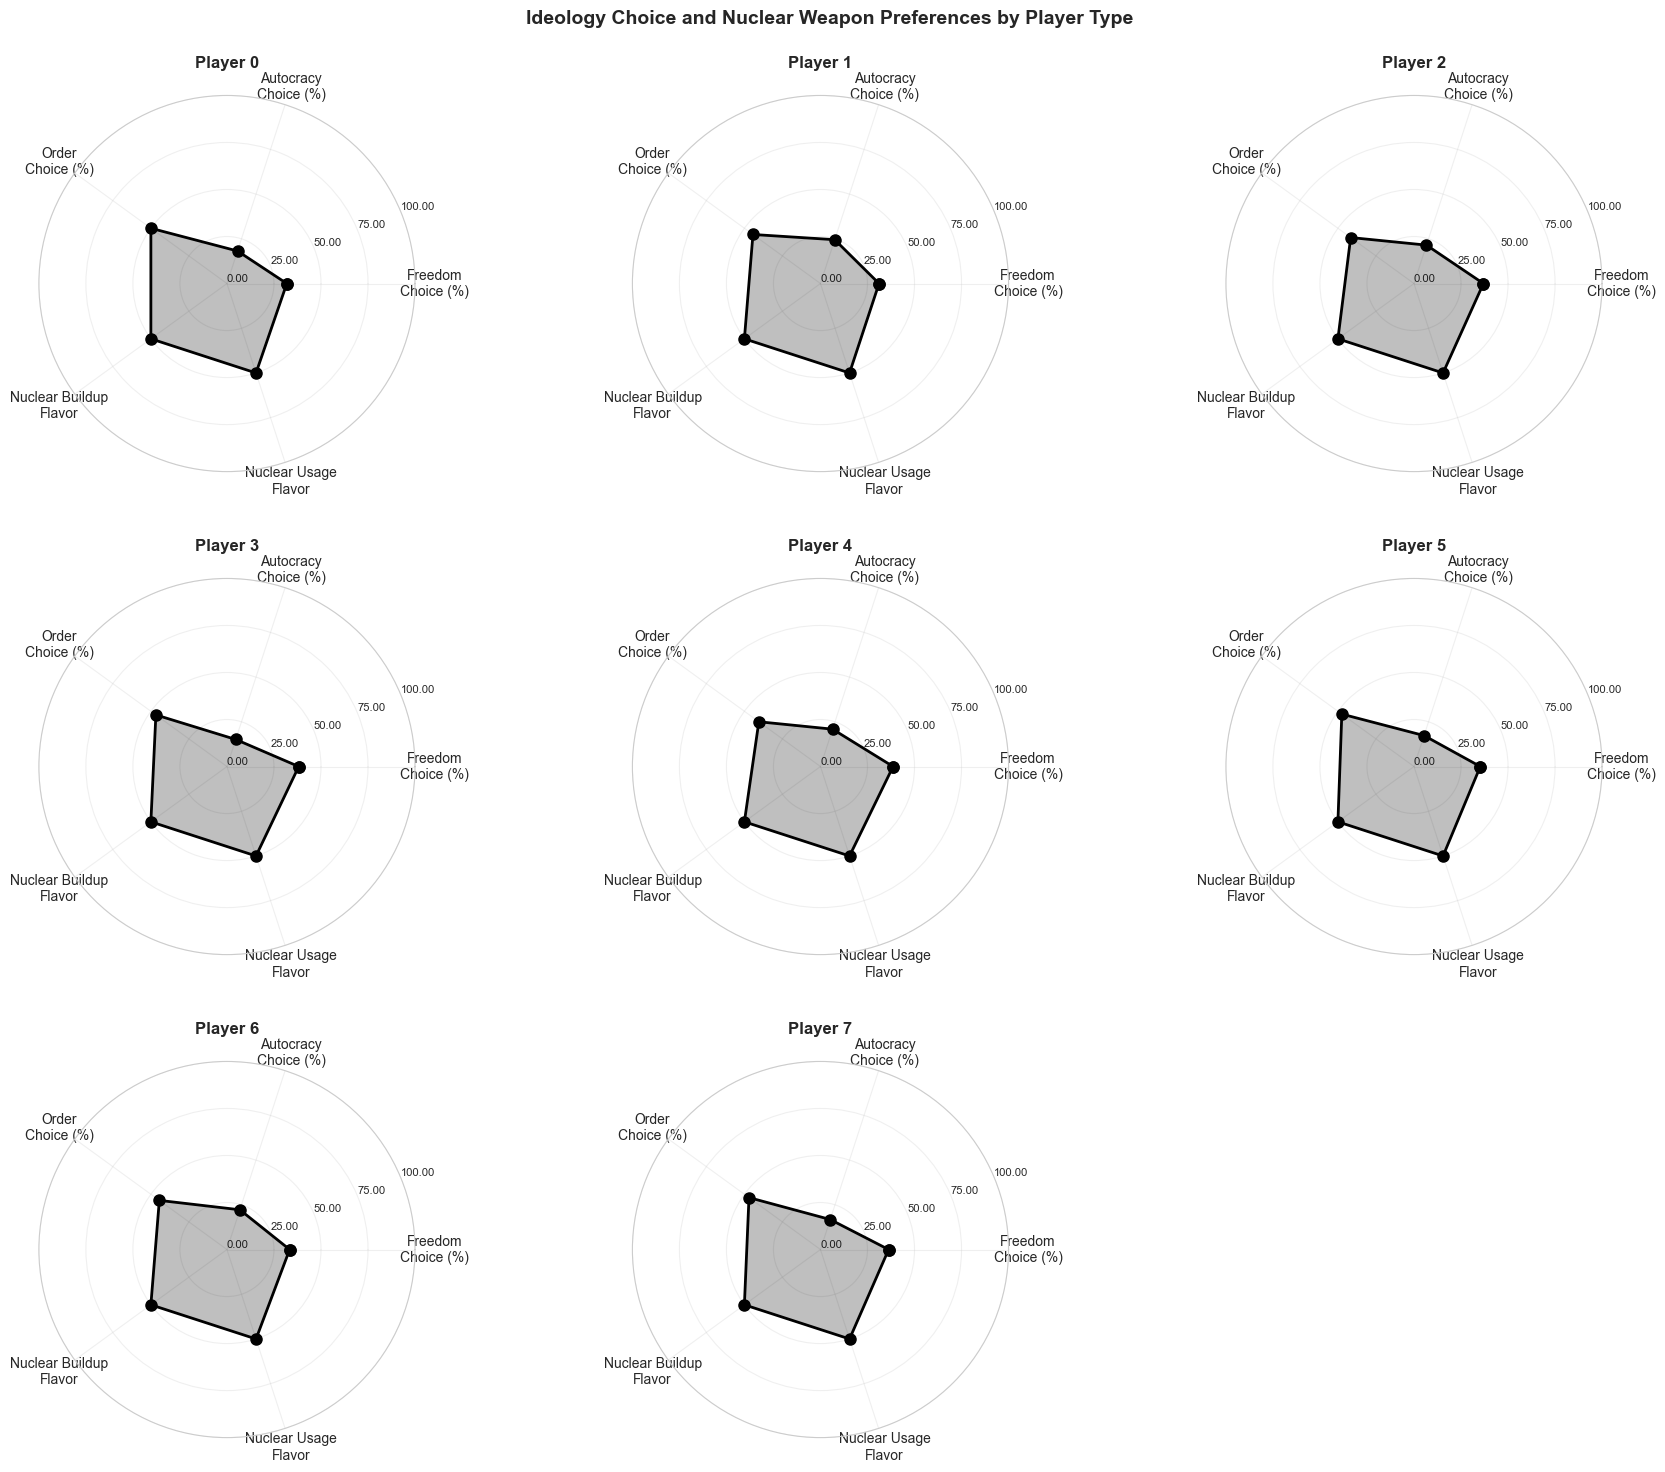


Ideology Choice and Nuclear Weapon Preferences by Player Type Summary:


c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2304: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2305: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc


,N,Freedom Choice (%),Autocracy Choice (%),Order Choice (%),Nuclear Buildup Flavor,Nuclear Usage Flavor
Player 0,194,"31.818 [24.379, 39.257]","18.182 [12.022, 24.342]","50.000 [42.014, 57.986]","50.000 [nan, nan]","50.000 [nan, nan]"
Player 1,194,"31.126 [23.656, 38.596]","24.503 [17.564, 31.442]","44.371 [36.356, 52.386]","50.000 [nan, nan]","50.000 [nan, nan]"
Player 2,194,"36.913 [29.074, 44.751]","21.477 [14.806, 28.147]","41.611 [33.604, 49.617]","50.000 [nan, nan]","50.000 [nan, nan]"
Player 3,194,"38.158 [30.347, 45.969]","15.132 [9.370, 20.894]","46.711 [38.689, 54.733]","50.000 [nan, nan]","50.000 [nan, nan]"
Player 4,194,"38.608 [30.933, 46.282]","20.886 [14.478, 27.294]","40.506 [32.768, 48.245]","50.000 [nan, nan]","50.000 [nan, nan]"
Player 5,194,"35.256 [27.676, 42.837]","17.308 [11.305, 23.310]","47.436 [39.513, 55.359]","50.000 [nan, nan]","50.000 [nan, nan]"
Player 6,194,"33.333 [25.779, 40.888]","22.222 [15.560, 28.884]","44.444 [36.482, 52.407]","50.000 [nan, nan]","50.000 [nan, nan]"
Player 7,194,"36.242 [28.433, 44.050]","16.779 [10.709, 22.848]","46.980 [38.873, 55.087]","50.000 [nan, nan]","50.000 [nan, nan]"


(<Figure size 1800x1500 with 9 Axes>,
 array([<PolarAxes: title={'center': 'Player 0'}>,
        <PolarAxes: title={'center': 'Player 1'}>,
        <PolarAxes: title={'center': 'Player 2'}>,
        <PolarAxes: title={'center': 'Player 3'}>,
        <PolarAxes: title={'center': 'Player 4'}>,
        <PolarAxes: title={'center': 'Player 5'}>,
        <PolarAxes: title={'center': 'Player 6'}>,
        <PolarAxes: title={'center': 'Player 7'}>, <PolarAxes: >],
       dtype=object))

In [4]:
# Choice of ideology (first adopted among freedom/autocracy/order)
ideology_cols = ['freedom', 'autocracy', 'order']
panel_df['ideology_choice'] = (
    panel_df[ideology_cols]
    .idxmin(axis=1)
    .where(panel_df[ideology_cols].notna().any(axis=1), None)
    .str.title()
)

# Create binary columns for each ideology choice (0-100 scale to match nuclear flavors)
# Only set values for games where an ideology was actually adopted
panel_df['freedom_pct'] = None
panel_df['autocracy_pct'] = None
panel_df['order_pct'] = None

# Only calculate for games with ideology choice
ideology_mask = panel_df['ideology_choice'].notna()
panel_df.loc[ideology_mask, 'freedom_pct'] = (panel_df.loc[ideology_mask, 'ideology_choice'] == 'Freedom').astype(float) * 100
panel_df.loc[ideology_mask, 'autocracy_pct'] = (panel_df.loc[ideology_mask, 'ideology_choice'] == 'Autocracy').astype(float) * 100
panel_df.loc[ideology_mask, 'order_pct'] = (panel_df.loc[ideology_mask, 'ideology_choice'] == 'Order').astype(float) * 100

# Create radar chart showing ideology choices and nuclear flavors by player type
plot_strategy_radar_charts(
    panel_df,
    columns=['freedom_pct', 'autocracy_pct', 'order_pct', 'nuke', 'use_nuke'],
    labels=['Freedom\nChoice (%)', 'Autocracy\nChoice (%)', 'Order\nChoice (%)', 
            'Nuclear Buildup\nFlavor', 'Nuclear Usage\nFlavor'],
    title='Ideology Choice and Nuclear Weapon Preferences by Player Type',
    ylim=(0, 100),
    print_summary=True
)

## 4. Survival Rate (Survival Turns / Game Length)

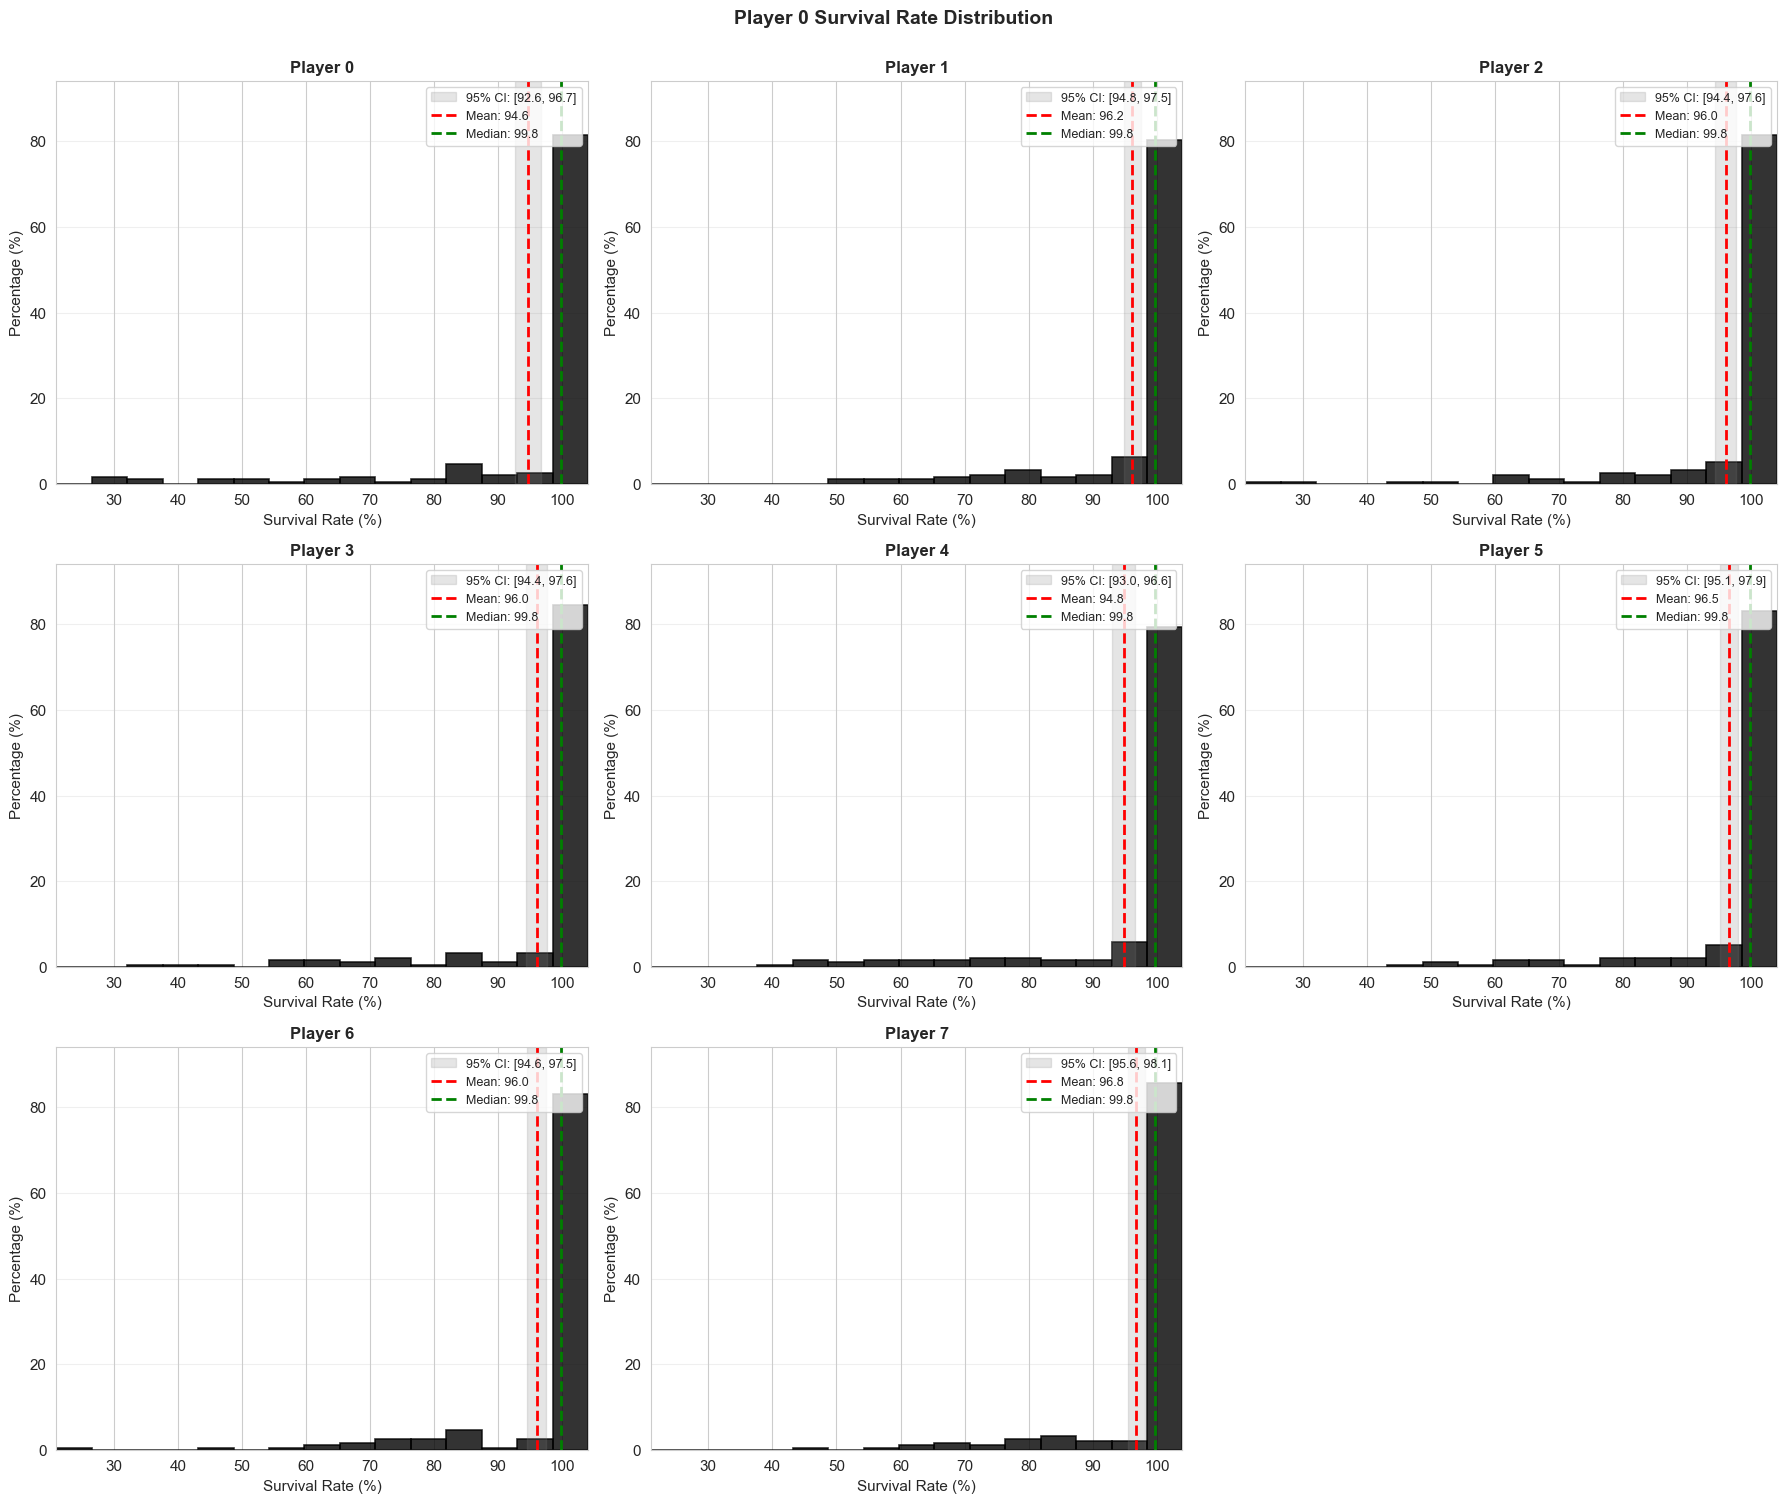


Player 0 Survival Rate Distribution Statistics:


,N,Mean,Median,Std,Min,Max,95% CI
Player 0,194,94.61,99.77,14.40,26.6,100.2,"[92.57, 96.65]"
Player 1,194,96.17,99.77,9.71,49.7,100.0,"[94.80, 97.55]"
Player 2,194,95.99,99.77,11.35,24.8,100.2,"[94.38, 97.60]"
Player 3,194,95.98,99.77,11.27,32.4,100.2,"[94.39, 97.58]"
Player 4,194,94.84,99.76,12.72,38.5,100.2,"[93.04, 96.64]"
Player 5,194,96.51,99.77,9.62,45.2,100.2,"[95.15, 97.87]"
Player 6,194,96.03,99.77,10.45,25.7,100.2,"[94.55, 97.51]"
Player 7,194,96.81,99.77,8.87,43.9,100.2,"[95.56, 98.07]"


In [5]:
# Calculate survival rate (survival turns / game length)
panel_df['survival_rate'] = panel_df['survival_turn'] / panel_df['turn'] * 100

# Use the reusable function for distribution histograms
plot_distribution_histograms(
    panel_df,
    'survival_rate',
    'Survival Rate (%)',
    'Player 0 Survival Rate Distribution'
)

## 5. Highest Ranking by Condition

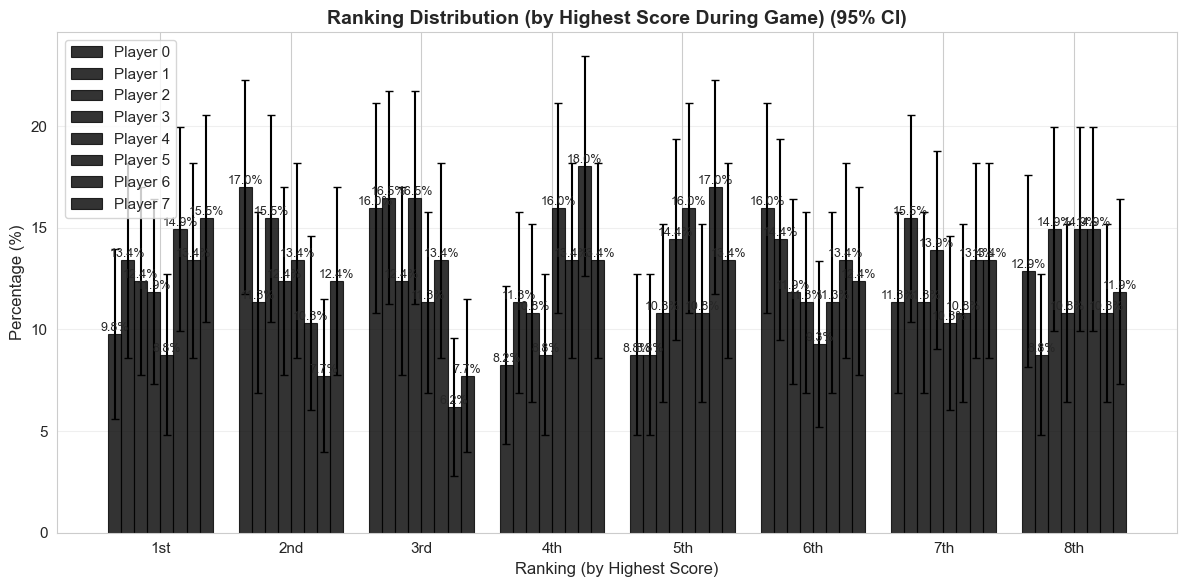

,1st,2nd,3rd,4th,5th,6th,7th,8th
Player 0,19 (9.8%),33 (17.0%),31 (16.0%),16 (8.2%),17 (8.8%),31 (16.0%),22 (11.3%),25 (12.9%)
Player 1,26 (13.4%),22 (11.3%),32 (16.5%),22 (11.3%),17 (8.8%),28 (14.4%),30 (15.5%),17 (8.8%)
Player 2,24 (12.4%),30 (15.5%),24 (12.4%),21 (10.8%),21 (10.8%),23 (11.9%),22 (11.3%),29 (14.9%)
Player 3,23 (11.9%),24 (12.4%),32 (16.5%),17 (8.8%),28 (14.4%),22 (11.3%),27 (13.9%),21 (10.8%)
Player 4,17 (8.8%),26 (13.4%),22 (11.3%),31 (16.0%),31 (16.0%),18 (9.3%),20 (10.3%),29 (14.9%)
Player 5,29 (14.9%),20 (10.3%),26 (13.4%),26 (13.4%),21 (10.8%),22 (11.3%),21 (10.8%),29 (14.9%)
Player 6,26 (13.4%),15 (7.7%),12 (6.2%),35 (18.0%),33 (17.0%),26 (13.4%),26 (13.4%),21 (10.8%)
Player 7,30 (15.5%),24 (12.4%),15 (7.7%),26 (13.4%),26 (13.4%),24 (12.4%),26 (13.4%),23 (11.9%)


In [6]:
# Player 0 ranking distribution (based on highest score during game)
plot_grouped_bar_chart(
    panel_df,
    value_col=None,  # Not used when use_percentage=True
    category_col='score_rank',
    xlabel='Ranking (by Highest Score)',
    ylabel='Percentage (%)',
    title='Ranking Distribution (by Highest Score During Game)',
    use_percentage=True,
    show_error_bars=True,
    x_labels=['1st', '2nd', '3rd', '4th', '5th', '6th', '7th', '8th']
)

## 6. Score Ratio Distribution

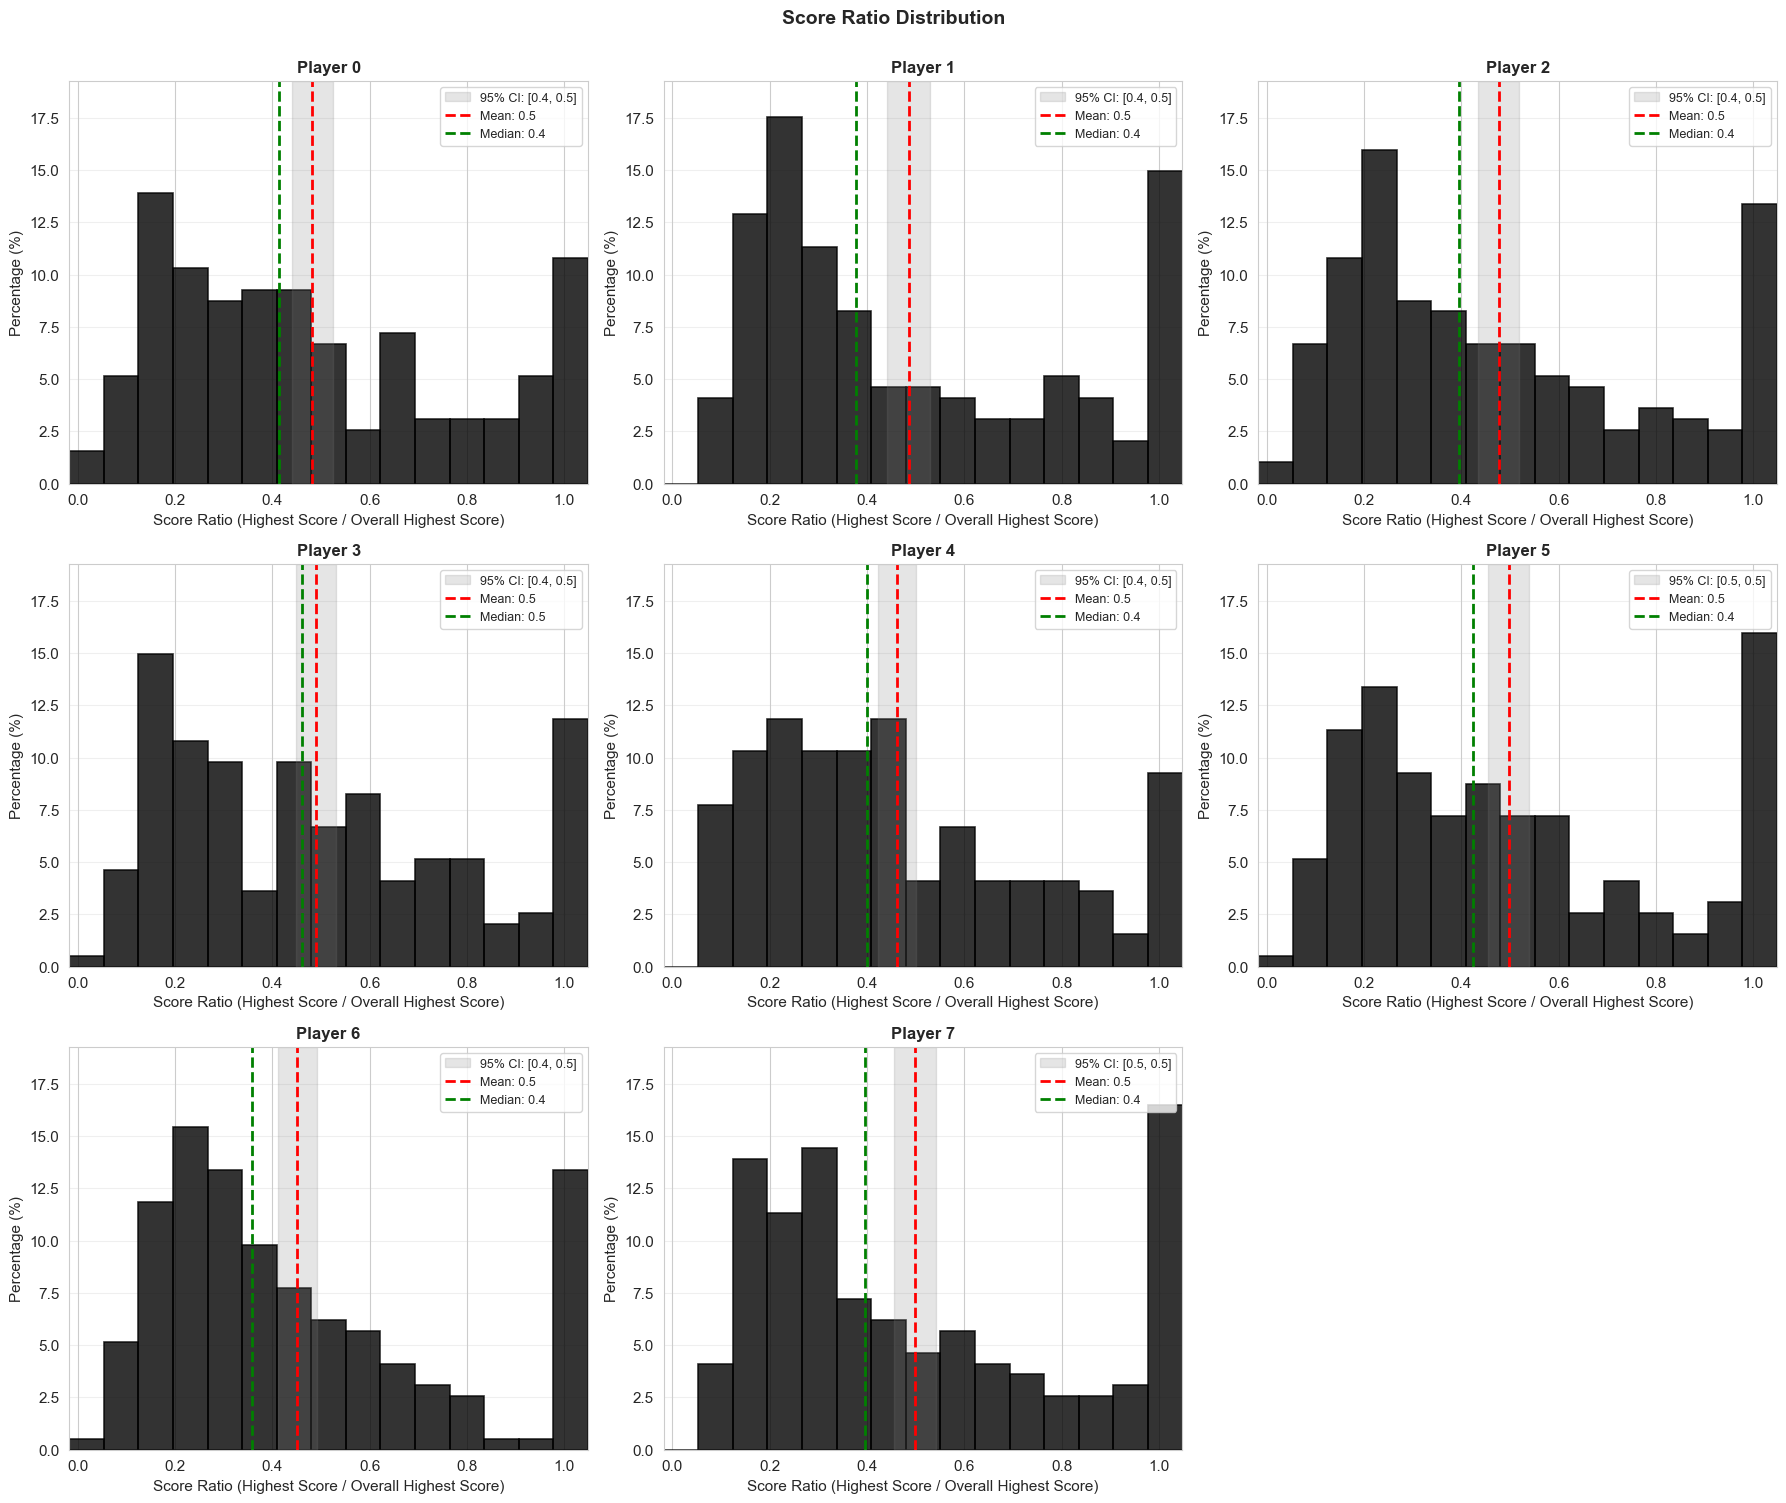


Score Ratio Distribution Statistics:


,N,Mean,Median,Std,Min,Max,95% CI
Player 0,194,0.48,0.41,0.30,0.0,1.0,"[0.44, 0.52]"
Player 1,194,0.49,0.38,0.31,0.1,1.0,"[0.44, 0.53]"
Player 2,194,0.48,0.40,0.30,0.0,1.0,"[0.43, 0.52]"
Player 3,194,0.49,0.46,0.29,0.0,1.0,"[0.45, 0.53]"
Player 4,194,0.46,0.40,0.28,0.1,1.0,"[0.42, 0.50]"
Player 5,194,0.50,0.42,0.30,0.0,1.0,"[0.45, 0.54]"
Player 6,194,0.45,0.36,0.28,0.0,1.0,"[0.41, 0.49]"
Player 7,194,0.50,0.40,0.31,0.1,1.0,"[0.45, 0.54]"


In [7]:
# Player 0 Score Ratio Distribution
plot_distribution_histograms(
    panel_df, 
    'score_ratio',
    'Score Ratio (Highest Score / Overall Highest Score)',
    'Score Ratio Distribution'
)

## 7. Nuke Behavior: Use-Nuke and Nuke Inclination

d:\Cache\Onedrive - Arizona\OneDrive - University of Arizona\Vox Deorum\nlp-2026-tiny-4player\analysis\exploratory\..\plot_utilities.py:1881: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  axes[idx].set_xlim(xlim)
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2304: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2305: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2304: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_dist

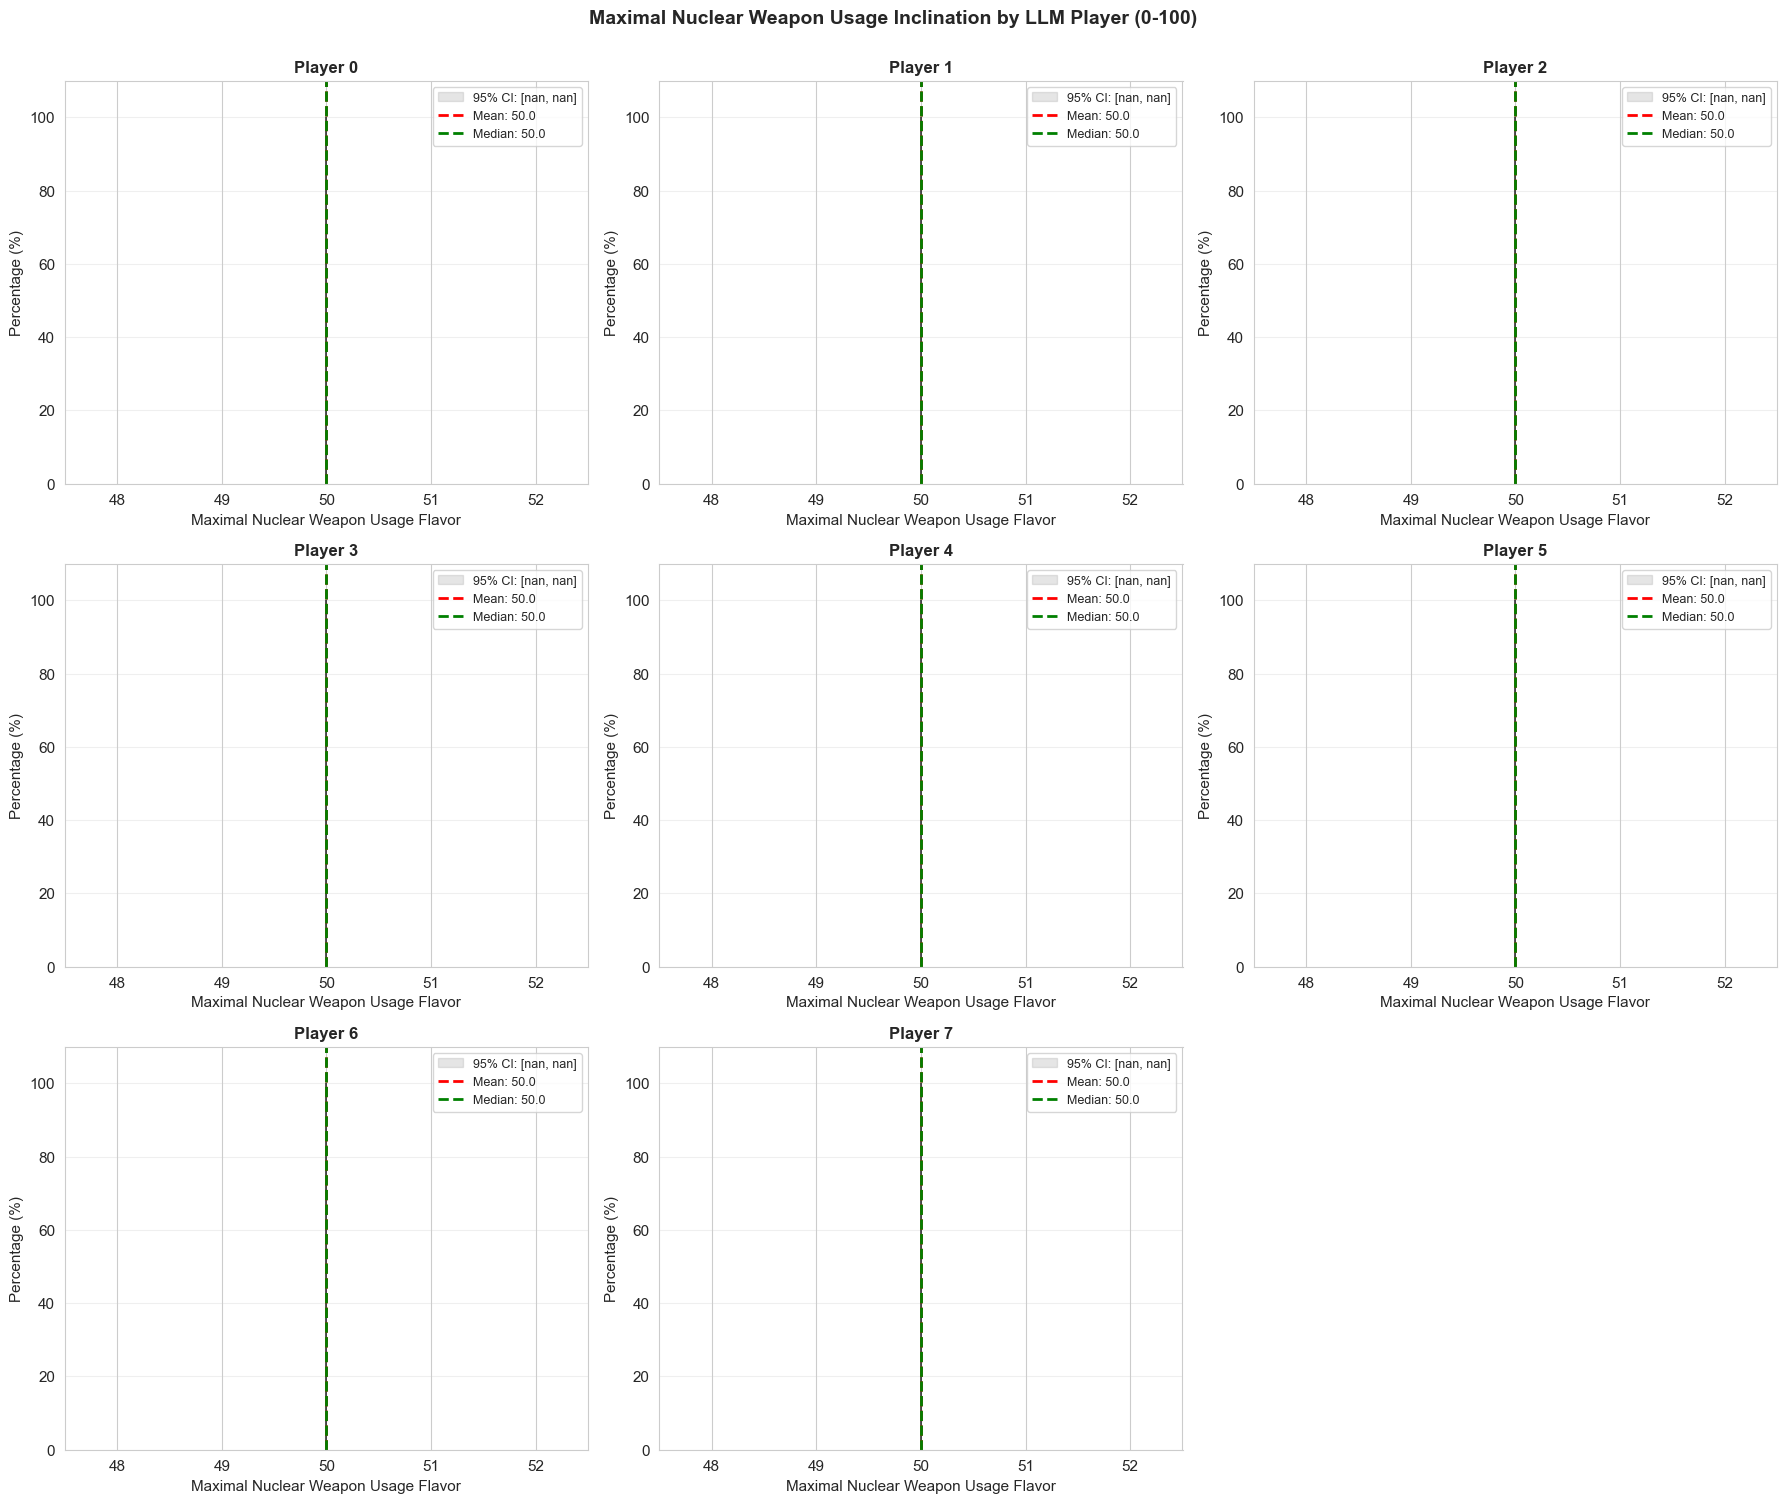


Maximal Nuclear Weapon Usage Inclination by LLM Player (0-100) Statistics:


c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2304: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2305: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2304: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2305: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2304: RuntimeWarning: invalid value encountered in multipl

,N,Mean,Median,Std,Min,Max,95% CI
Player 0,89,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"
Player 1,91,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"
Player 2,82,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"
Player 3,84,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"
Player 4,76,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"
Player 5,93,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"
Player 6,78,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"
Player 7,89,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"


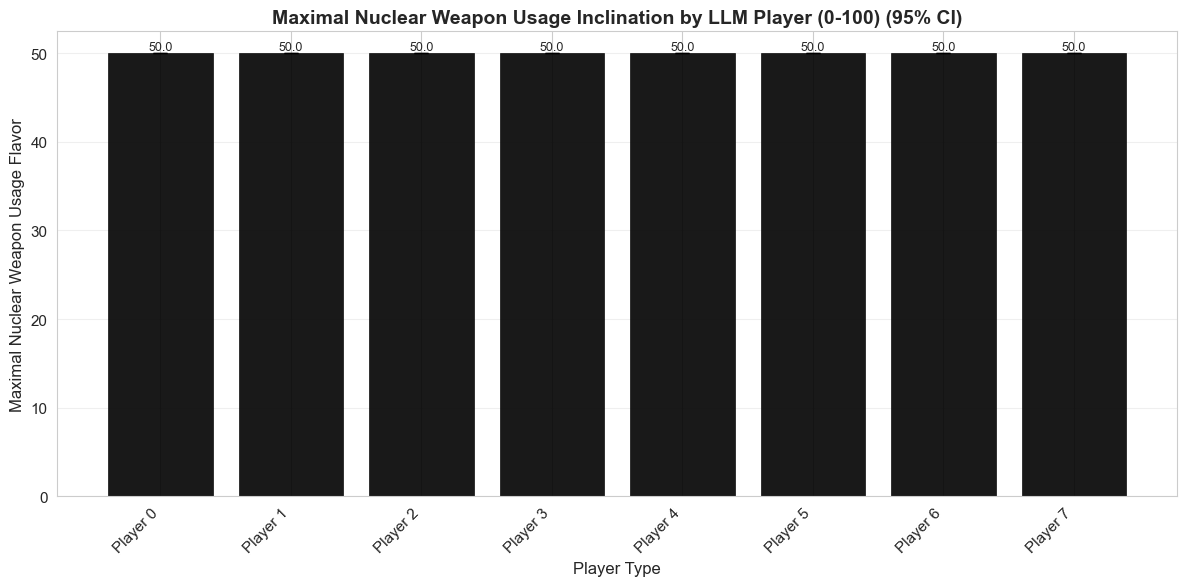

,Mean,Std,N
Player 0,50.0,0.0,89
Player 1,50.0,0.0,91
Player 2,50.0,0.0,82
Player 3,50.0,0.0,84
Player 4,50.0,0.0,76
Player 5,50.0,0.0,93
Player 6,50.0,0.0,78
Player 7,50.0,0.0,89


In [8]:
# Filter to LLM players only (exclude Vanilla)
llm_players = [pt for pt in panel_df['player_type'].unique() if pt != 'Vanilla' and pt != 'Null']

plot_distribution_histograms(
    panel_df,
    'use_nuke',
    'Maximal Nuclear Weapon Usage Flavor',
    'Maximal Nuclear Weapon Usage Inclination by LLM Player (0-100)',
    player_type_filter=llm_players
)

# Bar chart version with model-based colors
plot_bar_chart(
    panel_df[panel_df['player_type'].isin(llm_players)],
    value_col='use_nuke',
    category_col='player_type',
    xlabel='Player Type',
    ylabel='Maximal Nuclear Weapon Usage Flavor',
    title='Maximal Nuclear Weapon Usage Inclination by LLM Player (0-100)',
    figsize=(12,6),
    use_percentage=False,
    show_error_bars=True,
    color_by_category=True
)

d:\Cache\Onedrive - Arizona\OneDrive - University of Arizona\Vox Deorum\nlp-2026-tiny-4player\analysis\exploratory\..\plot_utilities.py:1881: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  axes[idx].set_xlim(xlim)
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2304: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2305: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2304: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_dist

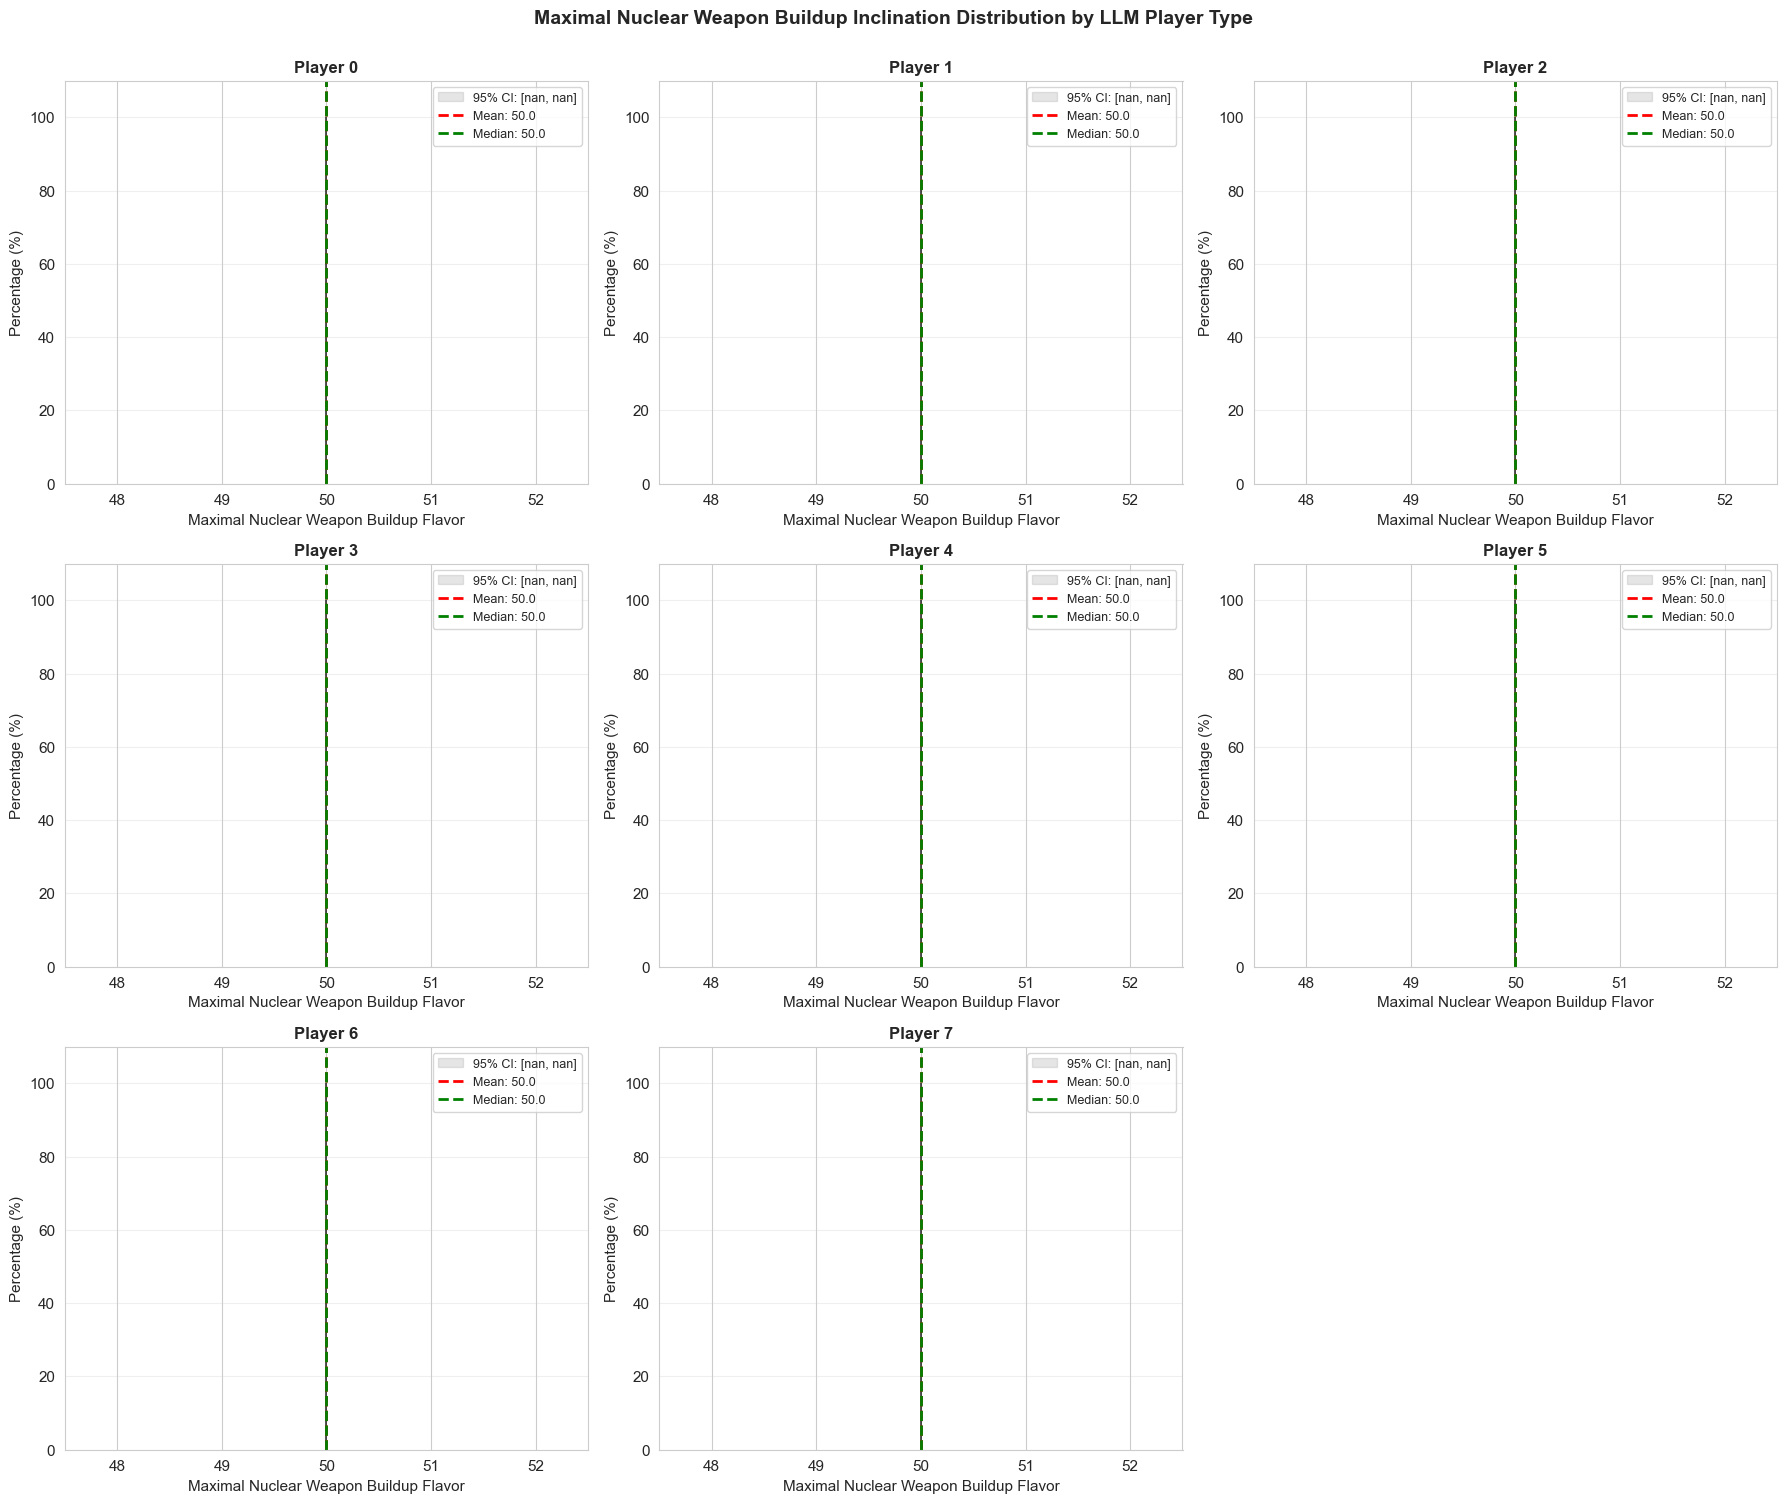


Maximal Nuclear Weapon Buildup Inclination Distribution by LLM Player Type Statistics:


c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2304: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2305: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2304: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2305: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2304: RuntimeWarning: invalid value encountered in multipl

,N,Mean,Median,Std,Min,Max,95% CI
Player 0,89,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"
Player 1,91,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"
Player 2,82,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"
Player 3,84,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"
Player 4,76,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"
Player 5,93,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"
Player 6,78,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"
Player 7,89,50.0,50.0,0.0,50.0,50.0,"[nan, nan]"


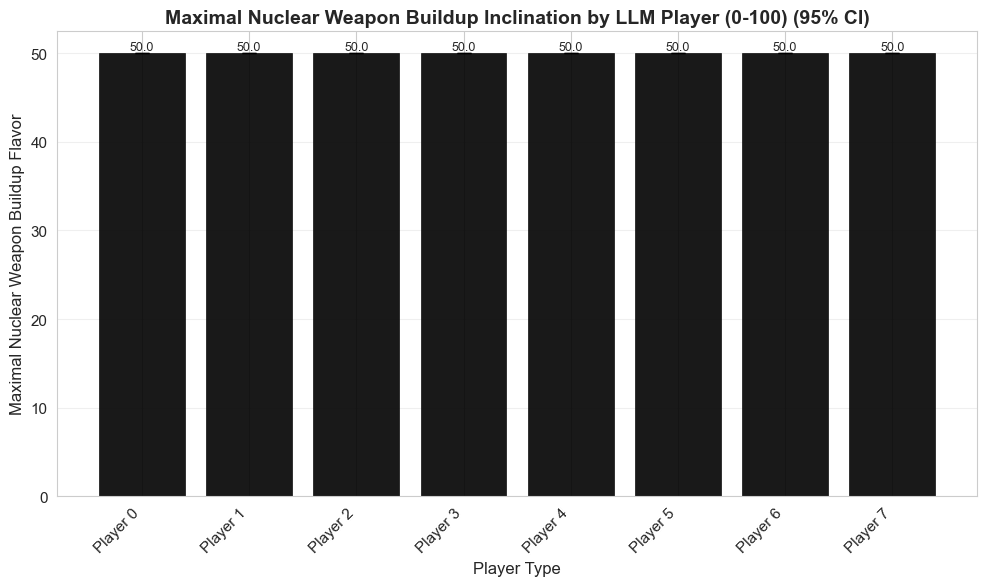

,Mean,Std,N
Player 0,50.0,0.0,89
Player 1,50.0,0.0,91
Player 2,50.0,0.0,82
Player 3,50.0,0.0,84
Player 4,50.0,0.0,76
Player 5,50.0,0.0,93
Player 6,50.0,0.0,78
Player 7,50.0,0.0,89


In [9]:
plot_distribution_histograms(
    panel_df,
    'nuke',
    'Maximal Nuclear Weapon Buildup Flavor',
    'Maximal Nuclear Weapon Buildup Inclination Distribution by LLM Player Type',
    player_type_filter=llm_players
)

# Bar chart version with model-based colors
plot_bar_chart(
    panel_df[panel_df['player_type'].isin(llm_players)],
    value_col='nuke',
    category_col='player_type',
    xlabel='Player Type',
    ylabel='Maximal Nuclear Weapon Buildup Flavor',
    title='Maximal Nuclear Weapon Buildup Inclination by LLM Player (0-100)',
    use_percentage=False,
    show_error_bars=True,
    color_by_category=True
)